# Supplemental Figure 4, Panel B

Barplots showing induction of expression following IFNg or Dex exposure at canonically-induced genes for each of thes stimuli. Points represent individual replicates. P-values calculated using one-sided Student's t-test

*Output: panelB_ifng.pdf, panelB_dex.pdf*

# Setup

In [2]:
#load packages
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/SuppFig4/PanelB/PanelB_example_genes.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

#Function to plot TPMs for genes of interest

plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name) #add gene name from row metadata
    temp <- temp %>% filter(gene_name == gene) #filter to only include gene of interest
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% #make into tidy format
                mutate(condition = gsub("_r.*$", "", name), #extract condition (dose + time) as well as dose and time separately
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_T.*$", "", condition)) %>% 
                filter(treatment %in% conditions) #filter to only include conditions of interest - this version is designed for pairwise comaprisons (2 conditions). If more conditions are needed, modify the ggplot implementation to include fill=condition
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition), #combine vehicle treated samples into one category
                            time=case_when(grepl("Veh", condition) ~ "T0", TRUE ~ time),
                           value=log2(value+1)) #log2 transform TPMs for plotting

    #statistical tests: is significant induction at t=1h and/or t=6h?
    p_t1 <- t.test(temp[temp$time=="T1",]$value, temp[temp$time=="T0",]$value, alternative="greater")$p.value 
    p_t6 <- t.test(temp[temp$time=="T6",]$value, temp[temp$time=="T0",]$value, alternative="greater")$p.value

    #plot results
    plot <- ggplot(temp, aes(x=time,y=value)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge(), fill="white") +  #mean TPM as column
        geom_point(position=position_jitter(height=0,width=.1), shape=21, size=2, fill="grey") + #individual replicates as points
        ggtitle(gene, subtitle=paste0("p(1h) = ", format(p_t1, digits=3), "\np(6h) = ", format(p_t6, digits=3))) + #report gene name and p-values in title
        ylab("Log2(TPM+1)") + coord_cartesian(ylim=c(0,9)) + scale_y_continuous(breaks=c(0,4,8))
    return(list(temp, plot))
}

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Load data

In [6]:
# TPMs
tpms <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "VST_abundance_batchCorr.tsv"
  ),
  sep = "\t"
)
# gene-level metadata
row.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "gene_metadata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "rsem_metadata.tsv"
  ),
  sep = "\t"
)

# Generate plots

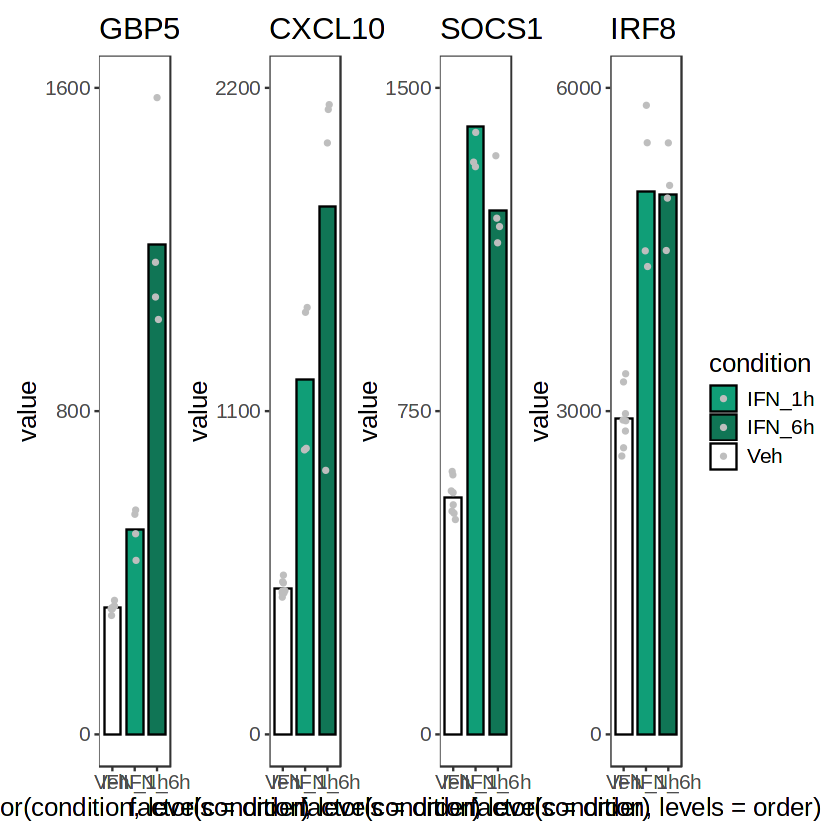

In [30]:
#IFNy
IFNy_targets <- c("GBP5", "IRF8", "CXCL10","SOCS1")
#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
order <- c("Veh", "IFN_1h", "IFN_6h")
ifn_cols <- c("Veh"="white", 
              "IFN_1h"="#109e77", 
              "IFN_6h"= "#107555")

plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name) #add gene name from row metadata
    temp <- temp %>% filter(gene_name == gene) #filter to only include gene of interest
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% #make into tidy format
                mutate(condition = gsub("_r.*$", "", name), #extract condition (dose + time) as well as dose and time separately
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_.h$", "", condition)) %>% 
                filter(treatment %in% conditions) 
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition), #combine vehicle treated samples into one category
                            time=case_when(grepl("Veh", condition) ~ "0h", TRUE ~ time),
                           value=2^value) #log2 transform TPMs for plotting
    #plot results
    plot <- ggplot(temp, aes(x=factor(condition, levels=order),y=value, fill=condition)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge()) +  #mean TPM as column
        geom_point(position=position_jitter(height=0,width=.1),  size=1, color="grey") + #individual replicates as points
        ggtitle(gene) +
        scale_fill_manual(values=ifn_cols)
    return(list(temp, plot))
}

#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
p1 <- plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))[[2]] + coord_cartesian(ylim=c(0,1600)) + scale_y_continuous(breaks=c(0,800,1600))
p2 <- plot_tpms(tpms, row.data, IFNy_targets[2], c("Veh", "IFN"))[[2]] + coord_cartesian(ylim=c(0,6000)) + scale_y_continuous(breaks=c(0,3000,6000))
p3 <- plot_tpms(tpms, row.data, IFNy_targets[3], c("Veh", "IFN"))[[2]] + coord_cartesian(ylim=c(0,2200)) + scale_y_continuous(breaks=c(0,1100,2200))
p4 <- plot_tpms(tpms, row.data, IFNy_targets[4], c("Veh", "IFN"))[[2]] + coord_cartesian(ylim=c(0,1500)) + scale_y_continuous(breaks=c(0,750,1500))

(p1 | p3 | p4 | p2) + plot_layout(guides="collect")
ggsave("panelB_ifny.pdf",width=11,height=3)

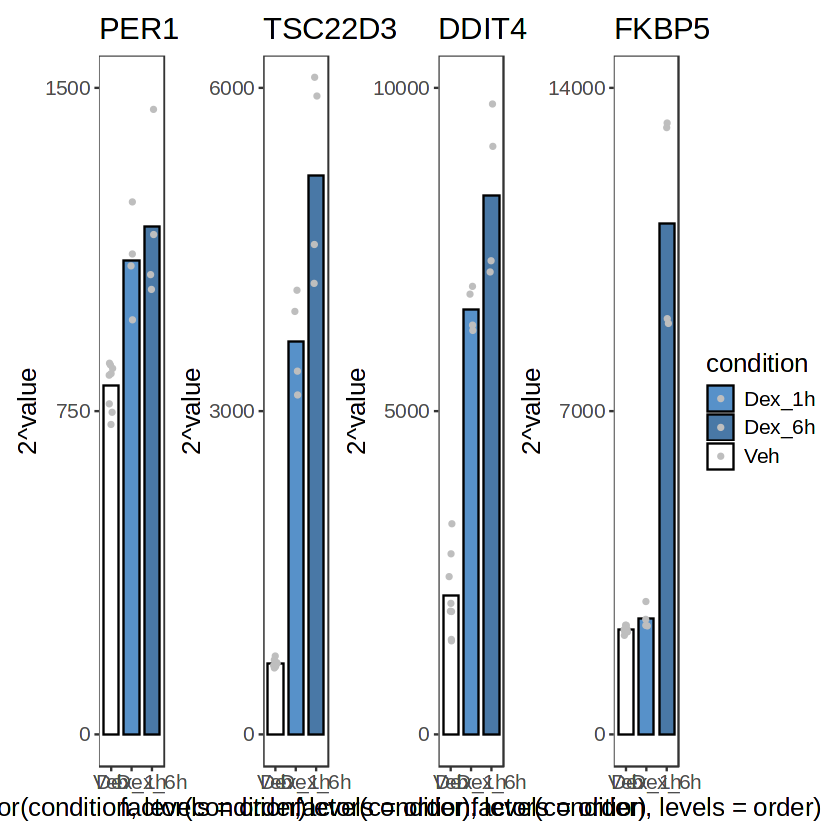

In [34]:
#Dex
order <- c("Veh", "Dex_1h", "Dex_6h")
dex_cols <- c("Veh"="white", 
              "Dex_1h"="#5791c9", 
              "Dex_6h"= "#4978a6")
plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name) #add gene name from row metadata
    temp <- temp %>% filter(gene_name == gene) #filter to only include gene of interest
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% #make into tidy format
                mutate(condition = gsub("_r.*$", "", name), #extract condition (dose + time) as well as dose and time separately
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_.h$", "", condition)) %>% 
                filter(treatment %in% conditions) 
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition), #combine vehicle treated samples into one category
                            time=case_when(grepl("Veh", condition) ~ "0h", TRUE ~ time)) #log2 transform TPMs for plotting

    #plot results
    plot <- ggplot(temp, aes(x=factor(condition, levels=order),y=2^value, fill=condition)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge()) +  #mean TPM as column
        geom_point(position=position_jitter(height=0,width=.1),  size=1, color="grey") + #individual replicates as points
        ggtitle(gene) + 
        scale_fill_manual(values=dex_cols)
    return(list(temp, plot))
}

Dex_targets <- c("DDIT4", "PER1", "TSC22D3","FKBP5")
#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
p1 <- plot_tpms(tpms, row.data, Dex_targets[1], c("Veh", "Dex"))[[2]] + coord_cartesian(ylim=c(0,10000)) + scale_y_continuous(breaks=c(0,5000,10000))
p2 <- plot_tpms(tpms, row.data, Dex_targets[2], c("Veh", "Dex"))[[2]] + coord_cartesian(ylim=c(0,1500)) + scale_y_continuous(breaks=c(0,750,1500))
p3 <- plot_tpms(tpms, row.data, Dex_targets[3], c("Veh", "Dex"))[[2]] + coord_cartesian(ylim=c(0,6000)) + scale_y_continuous(breaks=c(0,3000,6000))
p4 <- plot_tpms(tpms, row.data, Dex_targets[4], c("Veh", "Dex"))[[2]] + coord_cartesian(ylim=c(0,14000)) + scale_y_continuous(breaks=c(0,7000,14000))

(p2 | p3 | p1 | p4) + plot_layout(guides="collect")
ggsave("panelB_dex.pdf",width=11,height=3)

# stats

In [35]:
genes <- c("GBP5", "CXCL10", "SOCS1", "IRF8",
           "PER1", "TSC22D3", "DDIT4", "FKBP5")

pval_table <- tidyr::expand_grid(gene = genes, time = c(1, 6)) %>%
  mutate(
    stimulus = if_else(gene %in% genes[1:4], "IFN", "Dex"),
    stats = purrr::pmap(
      list(gene, time, stimulus),
      function(g, timepoint, stim) {
        i <- which(row.data$gene_name == g)
        stopifnot(length(i) == 1)                      # guard: one row per gene_name

        stim_cols <- paste0(stim,  "_", timepoint, "h_r", 1:4)
        veh_cols  <- paste0("Veh_", timepoint, "h_r", 1:4)    # shared vehicle, same timepoint
        stopifnot(all(c(stim_cols, veh_cols) %in% colnames(tpms)))

        x <- 2^(as.numeric(unlist(tpms[i, stim_cols])))   # stimulus
        y <- 2^(as.numeric(unlist(tpms[i, veh_cols])))   # vehicle
        tt <- t.test(x, y, var.equal = TRUE, alternative="greater") #test wheter stim expression is greater than controls

        tibble::tibble(p_raw = tt$p.value)
      }
    )
  ) %>%
  tidyr::unnest(stats) %>%
  group_by(stimulus) %>% # multiple test correct per stimulus
  mutate(
    padj = p.adjust(p_raw, method = "bonferroni"),
    sig = case_when(
      padj < 0.001     ~ "***",
      padj < 0.01      ~ "**",
      padj < 0.05      ~ "*",
      TRUE             ~ ""
    )
  ) %>%
  ungroup()

pval_table
write.table(pval_table, "pval_table.tsv", row.names=F, sep='\t')

gene,time,stimulus,p_raw,padj,sig
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
GBP5,1,IFN,3.050694e-04,2.440555e-03,**
GBP5,6,IFN,1.716571e-04,1.373257e-03,**
CXCL10,1,IFN,1.171946e-03,9.375568e-03,**
CXCL10,6,IFN,2.345797e-03,1.876638e-02,*
SOCS1,1,IFN,8.045396e-06,6.436317e-05,***
SOCS1,6,IFN,5.010291e-06,4.008233e-05,***
IRF8,1,IFN,4.430468e-04,3.544374e-03,**
IRF8,6,IFN,9.307703e-05,7.446163e-04,***
PER1,1,Dex,1.117736e-03,8.941890e-03,**
